In [1]:
#read in 733 sample x 3.5+ million DHS presence/absence matrix
import pandas as pd
import scipy as sp
import numpy as np
from lightfm import cross_validation
from lightfm.evaluation import precision_at_k
from lightfm.evaluation import recall_at_k
from lightfm.evaluation import auc_score
from lightfm import LightFM
import matplotlib.pyplot as plt
import pickle

In [21]:
dhs = pd.read_table('dat_bin_FDR01_hg38.txt.gz', header=None).T
dhs.shape

MemoryError: Unable to allocate 19.6 GiB for an array with shape (733, 3591898) and data type int64

In [ ]:
data_coo = sp.sparse.coo_matrix(dhs.values)

In [64]:
print(data_coo)

  (0, 20)	1
  (0, 53)	1
  (0, 63)	1
  (0, 85)	1
  (0, 86)	1
  (0, 133)	1
  (0, 134)	1
  (0, 194)	1
  (0, 204)	1
  (0, 253)	1
  (0, 257)	1
  (0, 259)	1
  (0, 261)	1
  (0, 263)	1
  (0, 268)	1
  (0, 271)	1
  (0, 322)	1
  (0, 330)	1
  (0, 381)	1
  (0, 421)	1
  (0, 427)	1
  (0, 429)	1
  (0, 436)	1
  (0, 462)	1
  (0, 525)	1
  :	:
  (732, 3591784)	1
  (732, 3591786)	1
  (732, 3591787)	1
  (732, 3591790)	1
  (732, 3591791)	1
  (732, 3591793)	1
  (732, 3591794)	1
  (732, 3591797)	1
  (732, 3591799)	1
  (732, 3591803)	1
  (732, 3591805)	1
  (732, 3591806)	1
  (732, 3591810)	1
  (732, 3591813)	1
  (732, 3591814)	1
  (732, 3591815)	1
  (732, 3591816)	1
  (732, 3591817)	1
  (732, 3591819)	1
  (732, 3591820)	1
  (732, 3591824)	1
  (732, 3591825)	1
  (732, 3591832)	1
  (732, 3591834)	1
  (732, 3591837)	1


In [7]:
#splitting data into train and test
(train, test) = cross_validation.random_train_test_split(data_coo, test_percentage=0.2, random_state=None)
data = {'train': train, 'test': test}

In [8]:
print((data))

{'train': <733x3591898 sparse matrix of type '<class 'numpy.float32'>'
	with 61022029 stored elements in COOrdinate format>, 'test': <733x3591898 sparse matrix of type '<class 'numpy.int64'>'
	with 15255508 stored elements in COOrdinate format>}


In [3]:
#creating model
model30_d1 = LightFM(no_components=1, loss='warp')

In [4]:
#training model
model30_d1.fit(data['train'], epochs=1, num_threads=2)

In [12]:
pickle_out_model = open('DHS_model30.pickle', 'wb')
pickle.dump(model30, pickle_out_model)
pickle_out_model.close()

pickle_out_data = open('DHS_data30.pickle', 'wb')
pickle.dump(data, pickle_out_data)
pickle_out_data.close()

In [3]:
pickle_in = open('DHS_model30.pickle', 'rb')
model=pickle.load(pickle_in)

pickle_in = open('DHS_data30.pickle', 'rb')
data=pickle.load(pickle_in)

In [6]:
with open('test_precision.txt') as f:
    test_precision = f.readlines()
print(test_precision)
with open('test_recall.txt') as f:
    test_recall = f.readlines()
print(test_recall)

['Test Precision@[1, 10, 100, 1000, 10000] = [0.14324693, 0.14215554, 0.14713506, 0.15518418, 0.16692564]']
['Test Recall@[1, 10, 100, 1000, 10000] = [1.0259158846487058e-05, 0.00010940640060583263, 0.001110367405831415, 0.011533907822787908, 0.1206632319817199]']


In [7]:
test_precision = [0.14324693, 0.14215554, 0.14713506, 0.15518418, 0.16692564]
test_recall = [1.0259158846487058e-05, 0.00010940640060583263, 0.001110367405831415, 0.011533907822787908, 0.1206632319817199]

In [ ]:
# measure precision/recall @ k for k=1:50
# test_precision = []
# test_recall = []
# train_precision = []
# train_recall = []

# for i in [1, 10, 100, 1000, 10000]:
#     test_precision.append(precision_at_k(model30_d1, data['test'], k=i).mean())
#     print('i')
#     test_recall.append(recall_at_k(model30, data['test'], k=i).mean())
#     train_precision.append(precision_at_k(model30, data['train'], k=i).mean())
#     train_recall.append(recall_at_k(model30, data['train'], k=i).mean())
#     print("k=" + i + " Finished")

Text(0.5, 1.0, 'Precision-Recall Curves for DHS LightFM model')

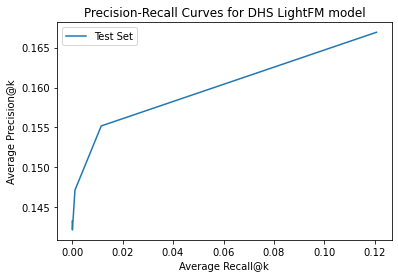

In [9]:
#Plot precision-recall curves for train and test data for both scaled and unscaled data
plt.plot(test_recall, test_precision)
# plt.plot(train_recall, train_precision)
# plt.plot(train_recall_scaled, train_precision_scaled)
# plt.plot(test_recall_scaled, test_precision_scaled)
plt.xlabel('Average Recall@k')
plt.ylabel('Average Precision@k')
plt.legend(['Test Set']) #, 'Train Set'
plt.title('Precision-Recall Curves for DHS LightFM model')
# plt.savefig('PR_Curves_DHS_LightFM_CT20210930.jpeg')

In [12]:
item_biases, item_embeddings = model.get_item_representations(features=None)
user_biases, user_embeddings = model.get_user_representations(features=None)

In [13]:
print(item_embeddings.shape)
print(user_embeddings)

(3591898, 10)
[[ 2.594112   -2.7120328   1.3811816  ...  2.0611312  -2.729041
  -3.6168811 ]
 [ 1.4131172   3.722523   -2.1493971  ... -1.370422   -0.6829925
  -1.4827424 ]
 [ 2.2060719  -1.6619732   3.2524655  ...  0.2379665  -2.3723385
  -3.6720824 ]
 ...
 [ 3.6081746   1.5524385   1.6069187  ... -0.9677343  -0.09321057
  -1.9476378 ]
 [ 2.599359    0.3400904   3.399262   ...  1.7615211   2.4782457
  -2.4411473 ]
 [ 2.5906262  -0.39559594  3.5373619  ...  2.1963093   2.1646953
  -2.6249156 ]]


In [ ]:
auc = auc_score(model, data['test'])

In [4]:
n_biosamples, n_dhs = data['train'].shape

In [22]:
scores = model.predict(24, np.arange(n_dhs))
#rank from most liked to least
top_items = [np.argsort(-scores)][0]
print(top_items[0:3])

[2898345  356003  209678]


In [73]:
tsv_file = open("DHS_Index_and_Vocabulary_metadata.tsv")
df = pd.read_csv(tsv_file, delimiter="\t")
print(df.head(20))

    library order Biosample name Vocabulary representative DCC Experiment ID  \
0               1        GM06990                       NaN       ENCSR000EMQ   
1               2          HepG2                       NaN       ENCSR000ENP   
2               3           hTH1                       NaN       ENCSR000EQC   
3               4           Hela                       NaN       ENCSR000ENO   
4               5          CACO2                       NaN       ENCSR000EMI   
5               6          CACO2                       NaN       ENCSR000EMI   
6               7          SKNSH                       NaN       ENCSR000EPZ   
7               8          SKNSH                       NaN       ENCSR000EPZ   
8               9           HMEC                       NaN       ENCSR000ENV   
9              10        GM12878                       NaN       ENCSR000EMT   
10             11           MCF7                       NaN       ENCSR000EPJ   
11             12           K562        

In [57]:
biosample_df = df[['library order', 'Biosample name']]

In [70]:
print(biosample_df[biosample_df['library order']==1]['Biosample name'][0])
print(biosample_df[biosample_df['Biosample name']=='GM06990']['library order'][0])

GM06990
1


In [108]:
DHS_metadata = pd.read_table('DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [116]:
#function to recommend DHSs for a given biosample. Takes in the model, data, and a list of
#biosamples for DHSs to be recommend for. For each biosample, prints out known associated DHSs
#and a list of recommended DHSs. Function modeled after tutorial 3, 'Recommendation Systems
#- Learn Python for Data Science' on LightFM github. 

def sample_recommendation(model, data, biosamples, recommend_num=5): #, full_data=gd_coo
    
    #number of diseases and genes in training dataset
    n_biosamples, n_DHSs = data['train'].shape
    
    #generate gene recommendations for each disease
    for biosample_name in biosamples:
        biosample = list(biosample_df[biosample_df['Biosample name']==biosample_name]['library order'])[0] - 1
#         disease_id = df[df['diseaseName'] == disease]['diseaseId'].tolist()[0]
#         disease_id_num = list(diseaseId_values).index(disease_id)
        #genes known to relate to the disease
        known_positives = [i for i, dhs_pos in enumerate(list(dhs.T[biosample])) if dhs_pos == 1]
#         known_positives = data['gene_ids'][np.argsort(-gd_coo.todense()[disease_id_num, :])]
#         known_ranked = list(np.squeeze(np.asarray(np.argsort(-gd_coo.todense()[disease_id_num, :]))))
#         print(known_ranked)
        
        #genes model predicts that relate to disease
        scores = model.predict(biosample, np.arange(n_DHSs))
#         print(np.argsort(-scores))
#         print(max(np.argsort(-scores)))
        #rank from most related to least
        top_DHSs = [np.argsort(-scores)][0]
        
        #print results
        
        print('Biosample: %s (%s)' %(biosample_name, str(biosample)))
        print('   Number of Known DHSs: %s' %(len(known_positives)))
        
#         known_pos = []
#         for DHS in known_positives[:5]:
#             geneId = data['gene_ids'][gene]
#             x = df[df['geneId'] == geneId]['geneSymbol'].tolist()[0]
#             known_pos.append(x)
#             print('      %s (%s)' %(x, association_score))
        
        print()
        print('   Recommended DHS Locations:')
        count = 0
        total_count = 0
        for DHS in top_DHSs[:]:
#             x = df[df['geneId'] == gene]['geneSymbol'].tolist()[0]
            total_count+=1
            if DHS not in known_positives:
                DHS_metadata_num = DHS+1
                count += 1
                chrom = DHS_metadata.iloc[DHS_metadata_num]['seqname']
                start = DHS_metadata.iloc[DHS_metadata_num]['start']
                end = DHS_metadata.iloc[DHS_metadata_num]['end']
                component = DHS_metadata.iloc[DHS_metadata_num]['component']
                num_samples = DHS_metadata.iloc[DHS_metadata_num]['numsamples']
                print('      %s:%s-%s, Component: %s, Number of Samples: %s' %(chrom, start, end, component, num_samples))
            if count == recommend_num:
                break
                
        print()
        print('Number of known positive recs before 5 new recs: %s' %(total_count))
            
sample_recommendation(model, data, ['GM06990'])

Biosample: GM06990 (0)
   Number of Known DHSs: 82918

   Recommended DHS Locations:
      chr6:43384040-43384240, Component: Lymphoid, Number of Samples: 2
      chr22:20463720-20464080, Component: Tissue invariant, Number of Samples: 1
      chr2:64283980-64284220, Component: Stromal B, Number of Samples: 46
      chr15:89017780-89018040, Component: Stromal A, Number of Samples: 67
      chr1:225467460-225467840, Component: Myeloid / erythroid, Number of Samples: 15

Number of known positive recs before 5 new recs: 129


In [5]:
test_dense = data['test'].todense()

In [51]:
#Precision for random recs
from random import sample
precision_list = []
for k in [1, 10, 100, 1000, 10000]:
    print(k)
    num = []
    for biosample in range(733):
        known_pos = [i for i, dhs_pos in enumerate(np.squeeze(np.asarray(test_dense[biosample]))) if dhs_pos == 1]
        rand_list = sample(range(0, n_dhs), k)
        rand_in_known = len([i for i in known_pos if i in rand_list])
        num.append(rand_in_known)
            
    num = np.array(num)
    precision = (num/k).mean()
    print(precision)
    precision_list.append(precision)

1
0.009549795361527967
10
0.006139154160982265
100
0.005334242837653479
1000
0.005875852660300137
10000
0.005817053206002729


In [59]:
#Recalculating precision 
from random import sample
precision_list_top = []
for k in [1, 10, 100, 1000, 10000]:
    print(k)
    num = []
    for biosample in range(733):
        scores = model.predict(biosample, np.arange(n_dhs)) 
        top_DHSs = [np.argsort(-scores)][0][0:k]
        known_pos = [i for i, dhs_pos in enumerate(np.squeeze(np.asarray(test_dense[biosample]))) if dhs_pos == 1]
        top_in_known = len([i for i in known_pos if i in top_DHSs])
        num.append(top_in_known)
            
    num = np.array(num)
    precision = (num/k).mean()
    print(precision)
    precision_list_top.append(precision)

1
0.1432469304229195
10
0.1421555252387449
100
0.1471487039563438
1000
0.15518417462482947
10000
0.1669268758526603
